# Pemodelan baseline YOLO11n dan usulan YOLO11m
Aprilia Dwi Cristyana — 1226800011

Jalankan setelah `01_EDA_Penanganan_Hasil_Akhir.ipynb`. Pilih **Runtime → Change
runtime type → GPU T4** di Colab. Notebook ini menyiapkan dua training pralatih
(fine-tuning), masing-masing maksimal 80 epoch, batch 8, imgsz 640, patience 15.

Dataset: 252 citra sumber terkoreksi; 3.342 anotasi. Train menjadi 525 file,
validation 50 dan test 27; total 602 file / 7.954 anotasi. Kedua model memakai
dataset, augmentasi, seed dan hyperparameter yang sama. Perbandingan ini
menguji ukuran arsitektur, bukan sekaligus perubahan preprocessing.

**Status saat paket disusun:** EDA sampai ekspor sudah dieksekusi tuntas.
Training/evaluasi 80 epoch pada notebook ini belum dieksekusi; tidak ada nilai
mAP, F1, confusion matrix atau Kappa hasil model yang direkayasa.

Path sudah diarahkan ke `MyDrive/1226800011_Aprilia_UjianEDA_Revisi`. Pilih GPU T4 lalu **Run all**. Jika dataset hasil belum tersedia, notebook 01 pada folder yang sama akan dijalankan otomatis. Hasil training tersimpan di `hasil_analisis/pemodelan`.


In [1]:
# Cell 1 — dependensi pemodelan. Colab sudah menyediakan PyTorch GPU.
import subprocess,sys
subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.3.221','scipy','pandas','pyyaml'])
import torch,ultralytics
print('Torch:',torch.__version__,'Ultralytics:',ultralytics.__version__)
if not torch.cuda.is_available():
    raise RuntimeError('Aktifkan T4 GPU Colab terlebih dahulu.')
print('GPU:',torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.11.0+cu130 Ultralytics: 8.3.221
GPU: Tesla T4


In [2]:
# Lokasi Drive sesuai folder yang diberikan pengguna.
from pathlib import Path, PurePosixPath
import os, json, hashlib, unicodedata, zipfile, shutil

PROJECT_NAME = '1226800011_Aprilia_UjianEDA_Revisi'
YOLO_FOLDER = 'enumerasi gigi susu6-252-.v1i.yolov11'
YOLO_ZIP = 'enumerasi_gigi_susu_252_label_asli.zip'

def normal_name(value):
    return ' '.join(unicodedata.normalize('NFKC', value).split()).casefold()

def get_project_root():
    try:
        from google.colab import drive
    except ImportError:
        # Hanya untuk verifikasi lokal. Di Colab, lokasi default tetap /content/drive.
        pass
    else:
        drive.mount('/content/drive')
    mydrive = Path(os.environ.get('FDI_MYDRIVE', '/content/drive/MyDrive'))
    direct = mydrive / PROJECT_NAME
    if direct.is_dir():
        return direct
    if not mydrive.is_dir():
        raise FileNotFoundError('Drive belum tersedia. Jalankan notebook ini di Google Colab dan izinkan akses Drive.')
    matches = [p for p in mydrive.iterdir()
               if p.is_dir() and normal_name(p.name) == normal_name(PROJECT_NAME)]
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Folder {PROJECT_NAME!r} belum ditemukan secara unik pada {mydrive}. '
            'Pastikan akun saat mount Drive adalah akun pemilik folder tersebut. '
            f'Kandidat: {matches}'
        )
    return matches[0]

def yolo_is_complete(root):
    images = root / 'train' / 'images'
    labels = root / 'train' / 'labels'
    if not ((root / 'data.yaml').is_file() and images.is_dir() and labels.is_dir()):
        return False
    paths = [p for p in images.iterdir()
             if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}]
    return len(paths) == 252 and all((labels / (p.stem + '.txt')).is_file() for p in paths)

def get_raw_yolo(project_root):
    unpacked = project_root / YOLO_FOLDER
    if yolo_is_complete(unpacked):
        print('Ekspor YOLO asli:', unpacked)
        return unpacked
    archive = project_root / YOLO_ZIP
    if not archive.is_file():
        raise FileNotFoundError(
            f'Ekspor YOLO dengan label FDI belum tersedia. Letakkan {YOLO_ZIP} '
            f'atau folder {YOLO_FOLDER} pada {project_root}. '
            'Empat folder sumber saja belum memuat label FDI yang diperlukan.'
        )
    digest = hashlib.sha256()
    with archive.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    scratch = Path(os.environ.get('FDI_SCRATCH', '/content'))
    extracted = scratch / ('fdi_raw_' + digest.hexdigest()[:12])
    root = extracted / YOLO_FOLDER
    if not yolo_is_complete(root):
        extracted.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            if z.testzip() is not None:
                raise RuntimeError('ZIP belum lengkap atau rusak. Tunggu unggahan selesai lalu jalankan ulang.')
            for info in z.infolist():
                rel = PurePosixPath(info.filename)
                if rel.is_absolute() or '..' in rel.parts or chr(92) in info.filename:
                    raise ValueError('ZIP memiliki lokasi file yang tidak aman.')
                if ((info.external_attr >> 16) & 0o170000) == 0o120000:
                    raise ValueError('ZIP dengan symbolic link tidak digunakan.')
                target = (extracted / Path(*rel.parts)).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError('Lokasi ekstraksi keluar dari folder tujuan.')
            z.extractall(extracted)
    if not yolo_is_complete(root):
        raise RuntimeError('Ekspor YOLO harus memuat data.yaml, 252 citra dan pasangan file label aslinya.')
    print('ZIP YOLO diekstrak otomatis ke penyimpanan lokal runtime:', root)
    return root

PROJECT_ROOT = get_project_root()
print('Folder proyek Drive:', PROJECT_ROOT)

PROJECT = PROJECT_ROOT / 'hasil_analisis'
SOURCE = PROJECT / 'dataset_terkoreksi'
completion_file = PROJECT / 'RUN_COMPLETE.json'
if not completion_file.is_file():
    print('Hasil notebook 01 belum tersedia. Menjalankan persiapan data otomatis terlebih dahulu...')
    first_notebook = PROJECT_ROOT / '01_EDA_Penanganan_Hasil_Akhir.ipynb'
    if not first_notebook.is_file():
        raise FileNotFoundError('Notebook 01 harus berada pada folder proyek yang sama.')
    from IPython.display import display
    first = json.loads(first_notebook.read_text(encoding='utf-8'))
    namespace = {'__name__':'auto_prepare_fdi','display':display}
    for number,cell in enumerate(first['cells'],1):
        if cell['cell_type']=='code':
            print(f'Persiapan data otomatis: cell {number}')
            exec(compile(''.join(cell['source']),f'auto_EDA_cell_{number}','exec'),namespace)
if not completion_file.is_file() or not (SOURCE/'manifest.csv').is_file():
    raise RuntimeError('Persiapan data belum selesai. Jalankan notebook 01 sampai cell terakhir.')
completion = json.loads(completion_file.read_text(encoding='utf-8'))
actual = hashlib.sha256((SOURCE/'manifest.csv').read_bytes()).hexdigest()
if completion.get('status')!='complete' or completion.get('manifest_sha256')!=actual:
    raise RuntimeError('Manifest hasil berubah atau proses belum lengkap. Jalankan ulang notebook 01.')
print('Dataset terkoreksi siap:',SOURCE)


Mounted at /content/drive
Folder proyek Drive: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi
Dataset terkoreksi siap: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_analisis/dataset_terkoreksi


In [3]:
# Cell 3 — salin hasil bersih ke penyimpanan lokal Colab agar training lebih cepat.
import pandas as pd
import yaml
from datetime import datetime
from zoneinfo import ZoneInfo
RUN_ID=datetime.now(ZoneInfo('Asia/Jakarta')).strftime('%Y%m%d_%H%M%S')
DATA_LOCAL=Path(os.environ.get('FDI_SCRATCH','/content'))/f'fdi_dataset_{RUN_ID}'
shutil.copytree(SOURCE,DATA_LOCAL)
config=yaml.safe_load((DATA_LOCAL/'data.yaml').read_text())
config['path']=str(DATA_LOCAL)
config.update(train='train/images',val='valid/images',test='test/images')
DATA_YAML=DATA_LOCAL/'data.yaml'
DATA_YAML.write_text(yaml.safe_dump(config,sort_keys=False),encoding='utf-8')
FDI=list(map(str,config['names']))
manifest=pd.read_csv(DATA_LOCAL/'manifest.csv')
assert len(manifest)==602 and manifest.image_id.nunique()==252
assert manifest.groupby('image_id').split.nunique().max()==1
assert manifest.groupby('group_id').split.nunique().max()==1
assert manifest.groupby('pixel_hash').split.nunique().max()==1
assert set(manifest[manifest.split!='train'].brightness_factor)=={1.}
for split,expected in {'train':525,'valid':50,'test':27}.items():
    assert len(list((DATA_LOCAL/split/'images').glob('*.png')))==expected
    assert len(list((DATA_LOCAL/split/'labels').glob('*.txt')))==expected
RUNS_HOME=PROJECT/'pemodelan'/RUN_ID
RUNS_HOME.mkdir(parents=True,exist_ok=True)
print('Dataset lokal:',DATA_LOCAL)
print('Hasil model tersimpan di Drive:',RUNS_HOME)

Dataset lokal: /content/fdi_dataset_20261031_124203
Hasil model tersimpan di Drive: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_analisis/pemodelan/20261031_124203


## Konfigurasi yang sama pada kedua model
Early stopping memantau fitness validation selama maksimal 80 epoch. Augmentasi brightness sudah dibuat pada train. Flip horizontal/vertikal dinonaktifkan karena mengubah sisi anatomis dan membutuhkan pemetaan ulang FDI. Augmentasi tambahan lain juga dinonaktifkan untuk perbandingan yang terkontrol.

In [4]:
"""Baseline YOLO11n vs YOLO11m. Training dipanggil di Colab GPU, bukan saat import."""
from pathlib import Path
import json,time
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

TRAIN_CONFIG=dict(imgsz=640,batch=8,epochs=80,patience=15,optimizer='AdamW',lr0=0.001,
                  weight_decay=0.0005,cos_lr=True,seed=42,deterministic=True,workers=2,
                  amp=True,pretrained=True,plots=True,save=True,val=True,cache=False,
                  mosaic=0.0,mixup=0.0,copy_paste=0.0,degrees=0.0,translate=0.0,scale=0.0,
                  shear=0.0,perspective=0.0,flipud=0.0,fliplr=0.0,
                  hsv_h=0.0,hsv_s=0.0,hsv_v=0.0,bgr=0.0)

def train_one(weights,data_yaml,runs_dir,name):
    import torch,ultralytics
    from ultralytics import YOLO
    if not torch.cuda.is_available():
        raise RuntimeError('Aktifkan GPU Colab: Runtime > Change runtime type > T4 GPU. Training CPU tidak dimulai otomatis.')
    model=YOLO(weights);start=time.time()
    # Train memakai validation, tidak memakai test untuk early stopping.
    model.train(data=str(data_yaml),device=0,project=str(runs_dir),name=name,exist_ok=False,**TRAIN_CONFIG)
    save_dir=Path(model.trainer.save_dir);best=save_dir/'weights'/'best.pt'
    if not best.is_file():raise RuntimeError('Training selesai tetapi best.pt tidak ditemukan.')
    hist=pd.read_csv(save_dir/'results.csv');hist.columns=hist.columns.str.strip()
    info=dict(model=weights,best=str(best),save_dir=str(save_dir),epochs_completed=len(hist),
              seconds=time.time()-start,ultralytics=ultralytics.__version__,torch=torch.__version__,
              gpu=torch.cuda.get_device_name(0),training_config=TRAIN_CONFIG)
    (save_dir/'run_metadata.json').write_text(json.dumps(info,indent=2),encoding='utf-8')
    del model
    torch.cuda.empty_cache()
    return info

def box_iou(gt,pred):
    gt=np.asarray(gt,dtype=float).reshape(-1,4);pred=np.asarray(pred,dtype=float).reshape(-1,4)
    if not len(gt) or not len(pred):return np.zeros((len(gt),len(pred)))
    lt=np.maximum(gt[:,None,:2],pred[None,:,:2]);rb=np.minimum(gt[:,None,2:],pred[None,:,2:])
    inter=np.maximum(rb-lt,0).prod(axis=2)
    area1=np.maximum(gt[:,2:]-gt[:,:2],0).prod(axis=1)
    area2=np.maximum(pred[:,2:]-pred[:,:2],0).prod(axis=1)
    return inter/np.maximum(area1[:,None]+area2[None,:]-inter,1e-12)

def match_boxes(gt,pred,iou_threshold=.5):
    ious=box_iou(gt,pred)
    if not ious.size:return []
    valid=ious>=iou_threshold
    # Maksimalkan jumlah pasangan valid dahulu, baru total IoU.
    score=valid.astype(float)+ious/(max(ious.shape)+1)
    rows,cols=linear_sum_assignment(score,maximize=True)
    return [(int(g),int(p)) for g,p in zip(rows,cols) if valid[g,p]]

def nominal_kappa(true,pred,num_classes=21):
    true=np.asarray(true,int);pred=np.asarray(pred,int)
    if not len(true):return float('nan')
    cm=np.zeros((num_classes,num_classes),int);np.add.at(cm,(true,pred),1)
    observed=np.trace(cm)/cm.sum()
    expected=(cm.sum(0)@cm.sum(1))/float(cm.sum()**2)
    return float((observed-expected)/(1-expected)) if not np.isclose(expected,1) else float('nan')

def evaluate_cache(records,confidence=.25,names=None,iou_threshold=.5):
    names=names or [str(i) for i in range(20)]
    k=len(names);cm=np.zeros((k+1,k+1),int);true_units=[];pred_units=[]
    image_rows=[]
    for r in records:
        keep=np.asarray(r['pred_conf'])>=confidence
        pb=np.asarray(r['pred_boxes']).reshape(-1,4)[keep]
        pc=np.asarray(r['pred_classes'],int)[keep]
        gb=np.asarray(r['gt_boxes']).reshape(-1,4);gc=np.asarray(r['gt_classes'],int)
        pairs=match_boxes(gb,pb,iou_threshold);used_g=set();used_p=set()
        for g,p in pairs:
            cm[gc[g],pc[p]]+=1;true_units.append(int(gc[g]));pred_units.append(int(pc[p]))
            used_g.add(g);used_p.add(p)
        for g in range(len(gc)):
            if g not in used_g:
                cm[gc[g],k]+=1;true_units.append(int(gc[g]));pred_units.append(k)
        for p in range(len(pc)):
            if p not in used_p:cm[k,pc[p]]+=1
        image_rows.append(dict(filename=r['filename'],gt=len(gc),pred=len(pc),matched=len(pairs)))
    tp=np.diag(cm)[:k];fp=cm.sum(0)[:k]-tp;fn=cm.sum(1)[:k]-tp
    precision=np.divide(tp,tp+fp,out=np.zeros(k,float),where=(tp+fp)>0)
    recall=np.divide(tp,tp+fn,out=np.zeros(k,float),where=(tp+fn)>0)
    f1=np.divide(2*tp,2*tp+fp+fn,out=np.zeros(k,float),where=(2*tp+fp+fn)>0)
    totals=dict(tp=int(tp.sum()),fp=int(fp.sum()),fn=int(fn.sum()))
    totals['precision_micro']=totals['tp']/max(1,totals['tp']+totals['fp'])
    totals['recall_micro']=totals['tp']/max(1,totals['tp']+totals['fn'])
    totals['f1_micro']=2*totals['tp']/max(1,2*totals['tp']+totals['fp']+totals['fn'])
    evaluated=(tp+fn)>0
    totals['f1_macro_present_classes']=float(f1[evaluated].mean()) if evaluated.any() else float('nan')
    totals['kappa_gt_units']=nominal_kappa(true_units,pred_units,k+1)
    totals['confidence_from_validation']=confidence;totals['match_iou']=iou_threshold
    table=pd.DataFrame(dict(FDI=names,TP=tp,FP=fp,FN=fn,precision=precision,recall=recall,F1=f1))
    return totals,table,cm,pd.DataFrame(image_rows)

def predict_cache(weights,dataset_root,split,device=0):
    from ultralytics import YOLO
    from PIL import Image
    root=Path(dataset_root);paths=sorted((root/split/'images').glob('*.png'))
    if not paths:raise FileNotFoundError(root/split/'images')
    model=YOLO(str(weights));records=[]
    stream=model.predict(source=list(map(str,paths)),stream=True,imgsz=640,batch=8,device=device,
                         conf=.001,iou=.7,max_det=300,verbose=False)
    for result in stream:
        p=Path(result.path);h,w=result.orig_shape;gt=[];classes=[]
        label=root/split/'labels'/(p.stem+'.txt')
        for line in label.read_text().splitlines():
            if not line.strip():continue
            c,x,y,bw,bh=map(float,line.split());classes.append(int(c))
            gt.append([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h])
        boxes=result.boxes
        records.append(dict(filename=p.name,gt_boxes=np.array(gt).reshape(-1,4),gt_classes=np.array(classes,int),
                            pred_boxes=boxes.xyxy.cpu().numpy(),pred_classes=boxes.cls.cpu().numpy().astype(int),
                            pred_conf=boxes.conf.cpu().numpy()))
    return records

def choose_threshold(weights,dataset_root,output_dir,names):
    # Pilih threshold dengan validation saja, kemudian kunci sebelum test.
    records=predict_cache(weights,dataset_root,'valid');rows=[]
    for threshold in np.arange(.05,.96,.05):
        metrics,_,_,_=evaluate_cache(records,float(threshold),names)
        rows.append(metrics)
    frame=pd.DataFrame(rows)
    frame.to_csv(Path(output_dir)/'threshold_validation.csv',index=False)
    best=frame.sort_values(['f1_micro','confidence_from_validation'],ascending=[False,True]).iloc[0]
    return float(best.confidence_from_validation)

def test_model(weights,data_yaml,dataset_root,output_dir,confidence,names):
    from ultralytics import YOLO
    import matplotlib.pyplot as plt
    output_dir=Path(output_dir);output_dir.mkdir(exist_ok=True,parents=True)
    model=YOLO(str(weights))
    result=model.val(data=str(data_yaml),split='test',imgsz=640,batch=8,device=0,
                     conf=.001,iou=.7,plots=True,project=str(output_dir),name='ultralytics_test',exist_ok=False)
    cache=predict_cache(weights,dataset_root,'test')
    summary,per_class,cm,per_image=evaluate_cache(cache,confidence,names)
    summary.update(map50=float(result.box.map50),map50_95=float(result.box.map))
    # AP untuk kelas tidak tersedia tidak diisi dengan rata-rata keseluruhan.
    present=set(map(int,result.box.ap_class_index))
    per_class['AP50_95']=[float(result.box.maps[i]) if i in present else np.nan for i in range(len(names))]
    per_class.to_csv(output_dir/'test_per_FDI.csv',index=False)
    per_image.to_csv(output_dir/'test_per_image.csv',index=False)
    pd.DataFrame(cm,index=names+['background'],columns=names+['background']).to_csv(output_dir/'confusion_matrix_gt_rows.csv')
    (output_dir/'test_metrics.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
    fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(cm,cmap='Blues')
    ax.set_xticks(range(len(names)+1),names+['BG'],rotation=90)
    ax.set_yticks(range(len(names)+1),names+['BG'])
    ax.set(xlabel='Prediksi',ylabel='Acuan',title=f'Confusion matrix — confidence validation {confidence:.2f}, IoU match 0.5')
    fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(output_dir/'confusion_matrix_gt_rows.png',dpi=160);plt.close(fig)
    return summary

display(pd.DataFrame(TRAIN_CONFIG.items(),columns=['parameter','nilai']))

,parameter,nilai
0,imgsz,640
1,batch,8
2,epochs,80
3,patience,15
4,optimizer,AdamW
5,lr0,0.001
6,weight_decay,0.0005
7,cos_lr,True
8,seed,42
9,deterministic,True


## Baseline sederhana — YOLO11n
Ini training GPU nyata. Jangan menganggap cell selesai sebelum checkpoint best.pt terbentuk.

In [5]:
BASELINE=train_one('yolo11n.pt',DATA_YAML,RUNS_HOME,'baseline_yolo11n')
(RUNS_HOME/'baseline_metadata.json').write_text(json.dumps(BASELINE,indent=2))
print(BASELINE)

New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.221 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/fdi_dataset_20261031_124203/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=False, name=baseline_yolo11n, nbs=6

## Model usulan — YOLO11m
Ukuran 640, batch 8, maksimal 80 epoch, early stopping patience 15. Jika GPU kehabisan memori, jangan diam-diam mengganti parameter salah satu model: gunakan GPU memadai atau dokumentasikan perubahan yang sama untuk kedua model.

In [6]:
PROPOSED=train_one('yolo11m.pt',DATA_YAML,RUNS_HOME,'usulan_yolo11m')
(RUNS_HOME/'usulan_metadata.json').write_text(json.dumps(PROPOSED,indent=2))
print(PROPOSED)

New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.221 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/fdi_dataset_20261031_124203/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.0, multi_scale=False, name=usulan_yolo11m, nbs=64,

## Pilih confidence dari validation lalu kunci
Confidence dipilih dari 0,05–0,95 berdasarkan micro F1 validation. Test belum dipakai pada pemilihan ini. IoU pencocokan objek adalah 0,5; parameter NMS IoU terpisah, yaitu 0,7.

In [7]:
models={'baseline_yolo11n':BASELINE,'usulan_yolo11m':PROPOSED}
thresholds={}
for name,info in models.items():
    output=RUNS_HOME/name/'evaluasi'
    output.mkdir(parents=True,exist_ok=True)
    thresholds[name]=choose_threshold(info['best'],DATA_LOCAL,output,FDI)
(RUNS_HOME/'confidence_validation.json').write_text(json.dumps(thresholds,indent=2))
print(thresholds)

{'baseline_yolo11n': 0.7500000000000001, 'usulan_yolo11m': 0.7000000000000001}


## Evaluasi akhir test
Laporkan mAP dari validator serta P/R/F1 pada confidence yang dipilih dari validation. Confusion matrix memakai baris acuan dan kolom prediksi, dengan background untuk objek hilang/berlebih. Kappa dihitung pada unit gigi acuan setelah pencocokan; objek terlewat mendapat kategori tidak terdeteksi. Prediksi berlebih tetap dihitung pada precision/F1 dan dilaporkan terpisah, karena tidak masuk unit Kappa acuan.

In [8]:
comparison=[]
for name,info in models.items():
    output=RUNS_HOME/name/'evaluasi'
    metrics=test_model(info['best'],DATA_YAML,DATA_LOCAL,output,thresholds[name],FDI)
    comparison.append({'model':name,**metrics})
comparison=pd.DataFrame(comparison)
comparison.to_csv(RUNS_HOME/'perbandingan_test.csv',index=False)
display(comparison)

Ultralytics 8.3.221 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,586,052 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 190.3±16.4 MB/s, size: 1571.2 KB)
val: Scanning /content/fdi_dataset_20261031_124203/test/labels... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 136.0it/s 0.2s
val: New cache created: /content/fdi_dataset_20261031_124203/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.8s
                   all         27        327      0.728      0.759      0.789      0.427
                    51          7          7      0.774       0.98      0.787      0.432
                    52         11         11      0.886      0.709       0.86      0.553
                    53         22         22      0.627          1      0.909      0.464
                    54         19         19   

,model,tp,fp,fn,precision_micro,recall_micro,f1_micro,f1_macro_present_classes,kappa_gt_units,confidence_from_validation,match_iou,map50,map50_95
0,baseline_yolo11n,227,43,100,0.840741,0.694190,0.760469,0.700947,0.680074,0.75,0.5,0.788892,0.427146
1,usulan_yolo11m,264,16,63,0.942857,0.807339,0.869852,0.856732,0.797738,0.70,0.5,0.903407,0.538071


## Grafik dan tabel per FDI
File results.csv menunjukkan jumlah epoch aktual; early stopping dapat menghentikan training sebelum epoch 80. best.pt dipilih dari validation, bukan test.

baseline_yolo11n epoch aktual: 59


,FDI,TP,FP,FN,precision,recall,F1,AP50_95
0,51,4,0,3,1.000000,0.571429,0.727273,0.432345
1,52,6,1,5,0.857143,0.545455,0.666667,0.553336
2,53,18,3,4,0.857143,0.818182,0.837209,0.464325
3,54,16,3,3,0.842105,0.842105,0.842105,0.467260
4,55,21,0,5,1.000000,0.807692,0.893617,0.515035
5,61,4,0,3,1.000000,0.571429,0.727273,0.504519
6,62,6,3,8,0.666667,0.428571,0.521739,0.297761
7,63,15,3,5,0.833333,0.750000,0.789474,0.401865
8,64,14,0,6,1.000000,0.700000,0.823529,0.446903
9,65,19,2,5,0.904762,0.791667,0.844444,0.477690


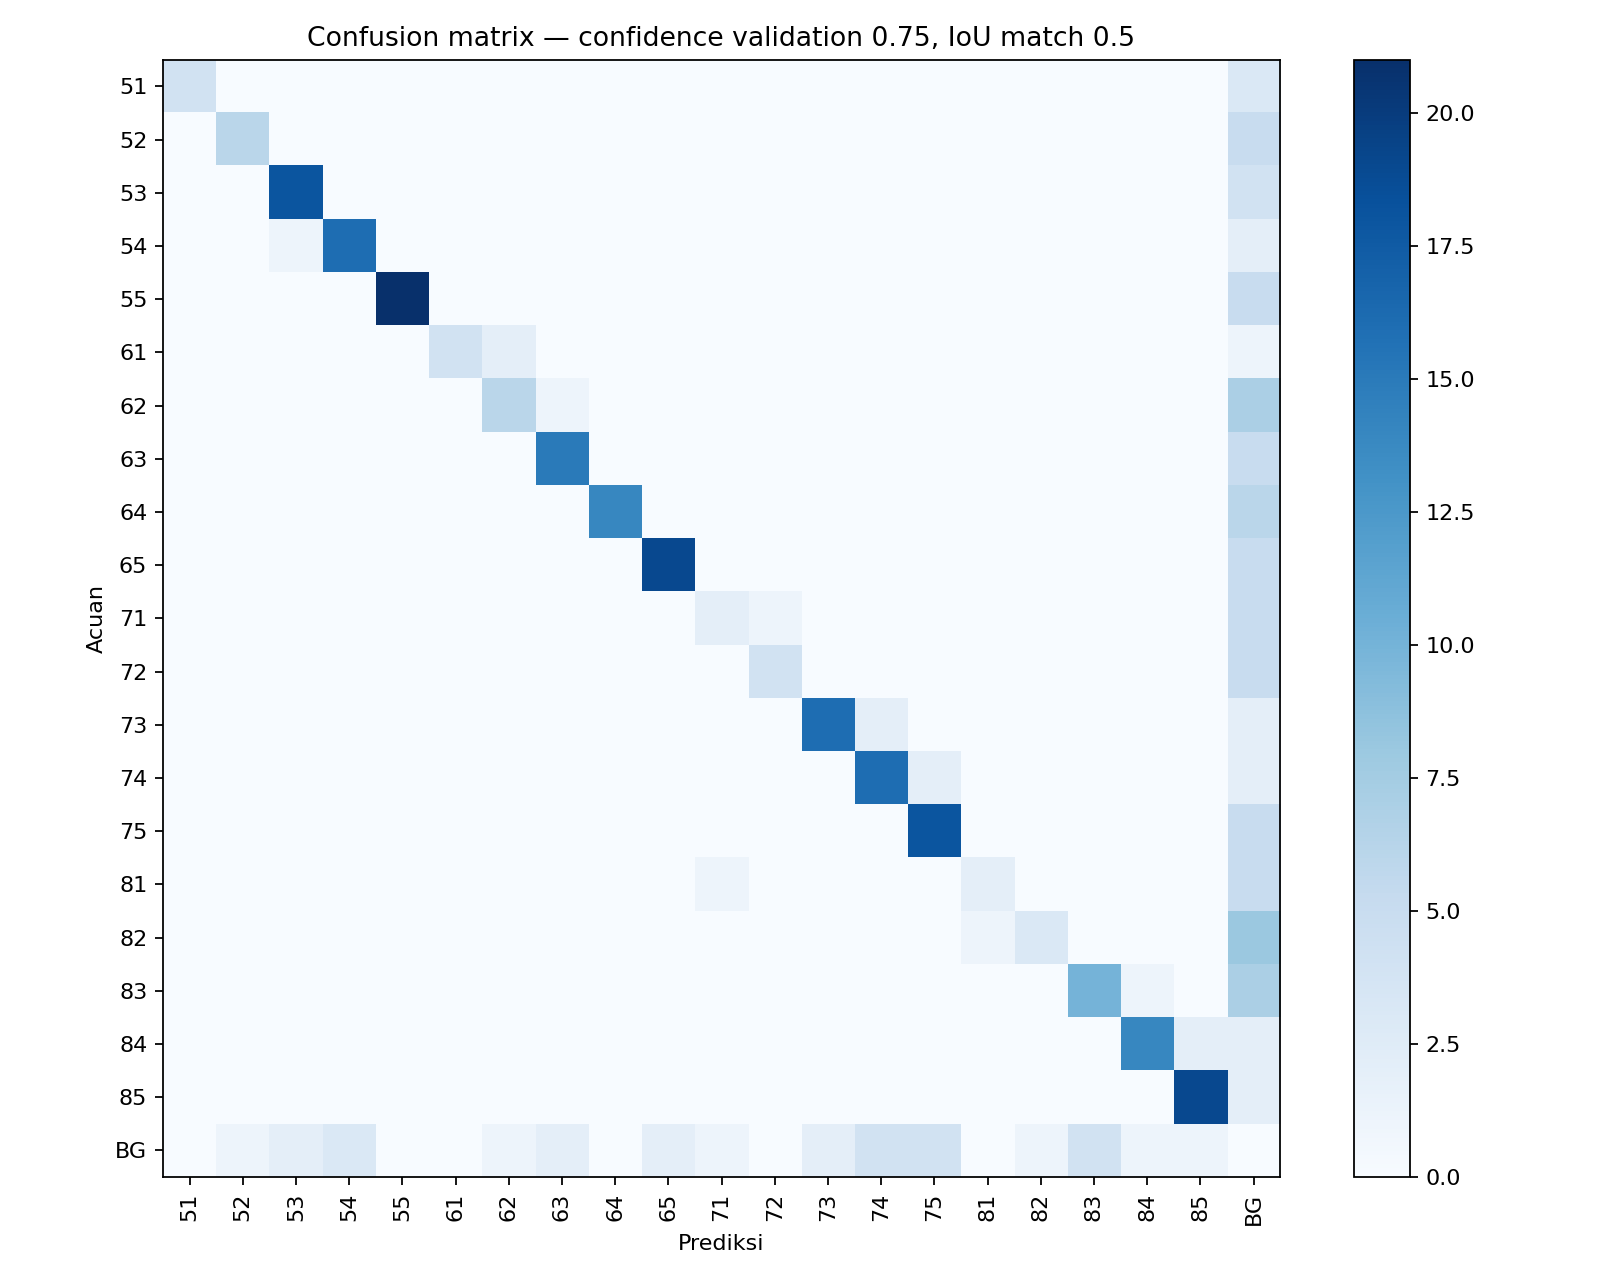

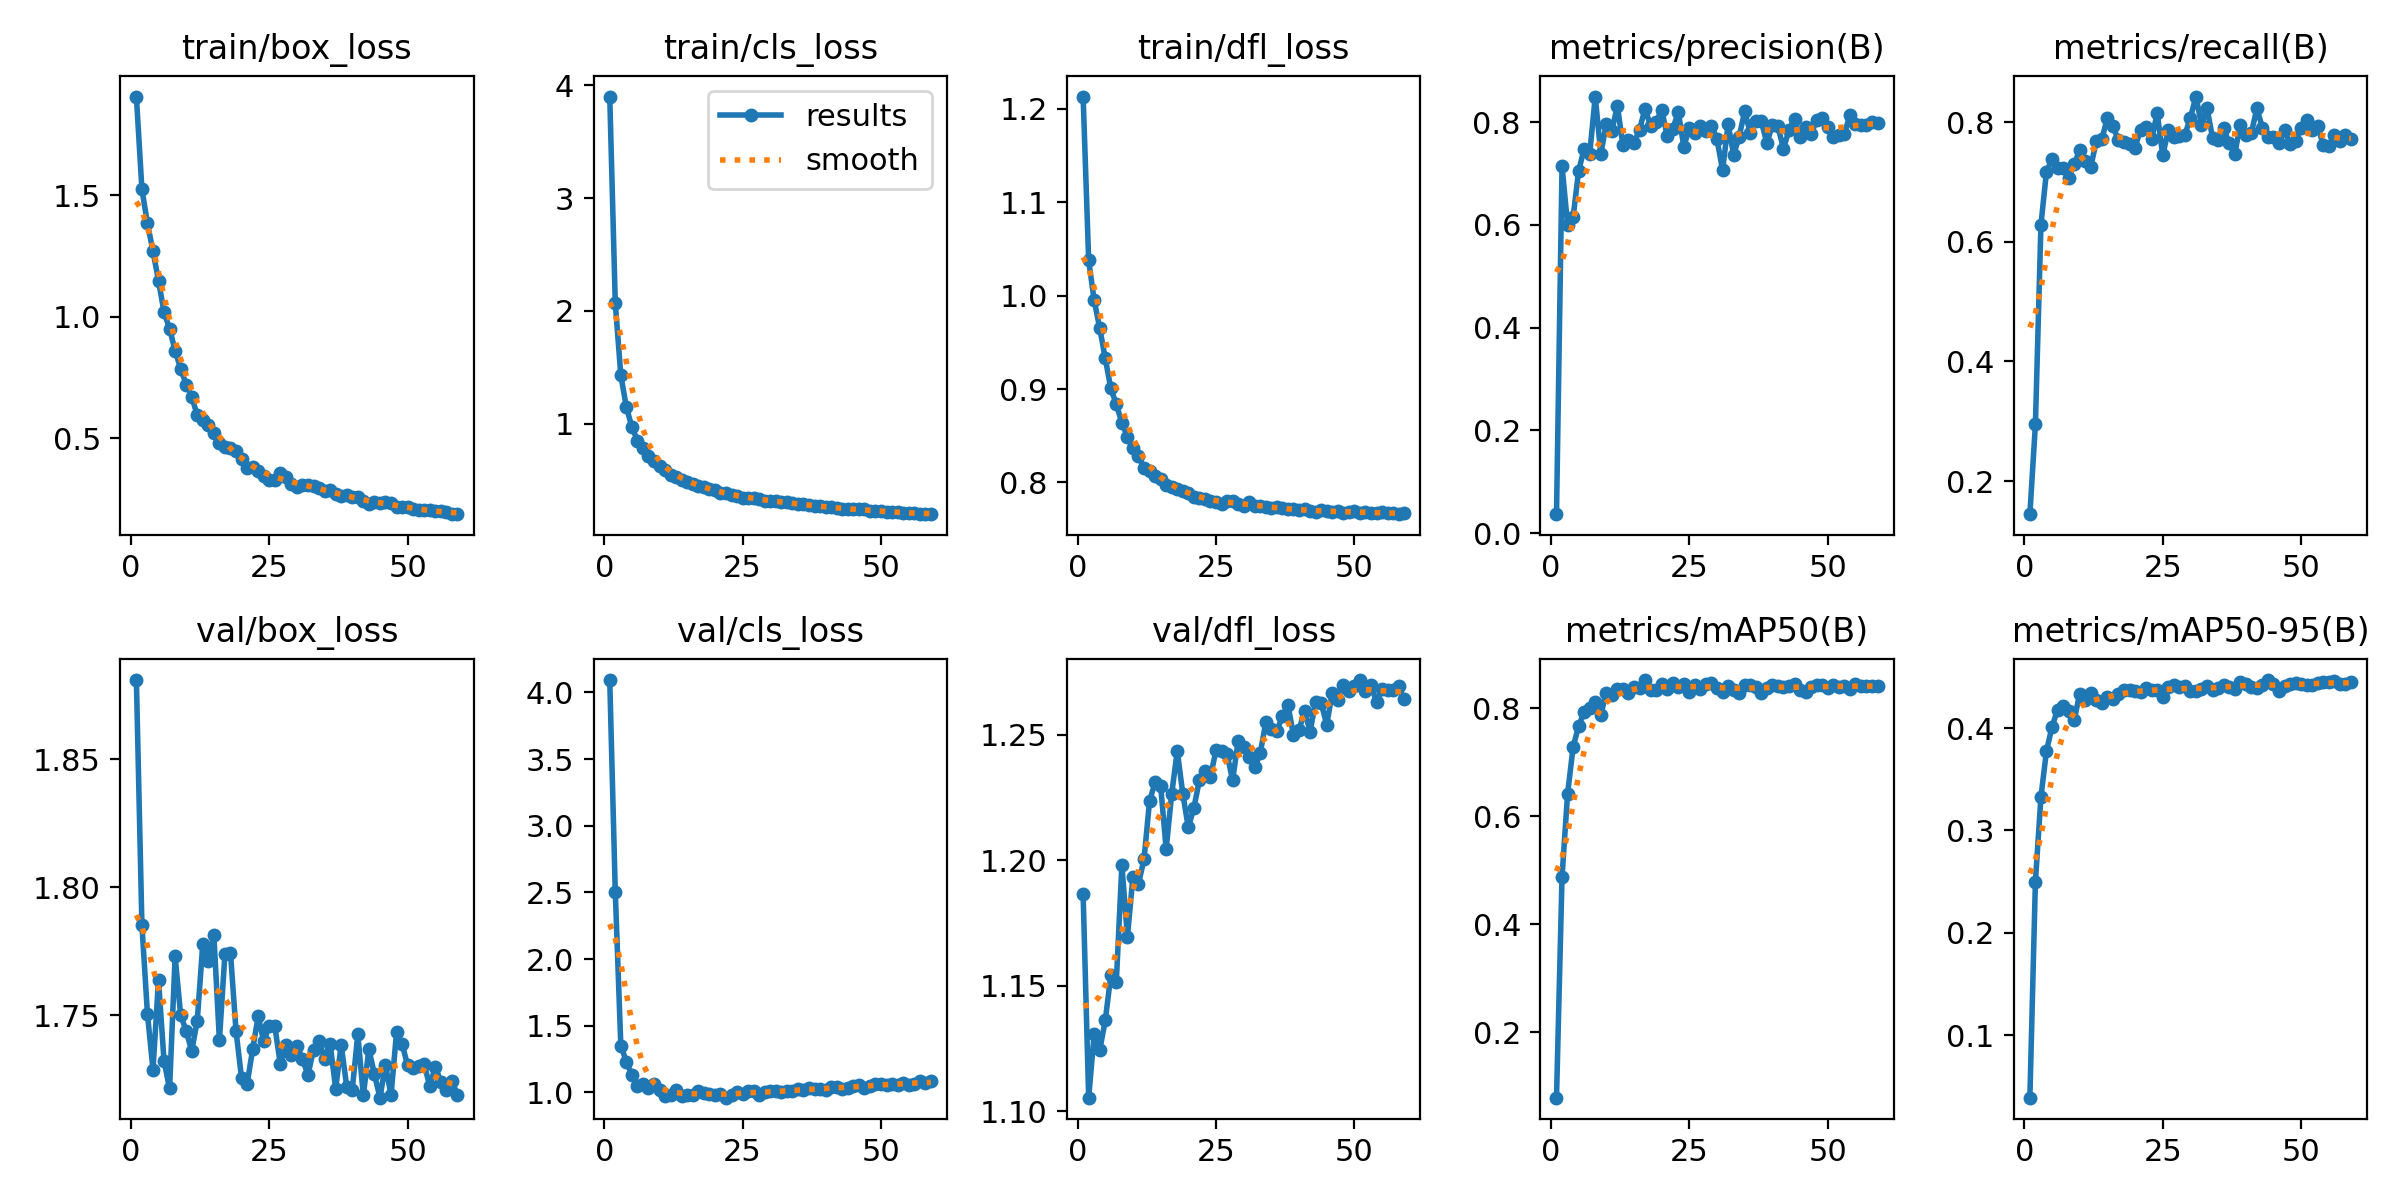

usulan_yolo11m epoch aktual: 69


,FDI,TP,FP,FN,precision,recall,F1,AP50_95
0,51,6,0,1,1.000000,0.857143,0.923077,0.697123
1,52,10,1,1,0.909091,0.909091,0.909091,0.558280
2,53,18,3,4,0.857143,0.818182,0.837209,0.568706
3,54,17,0,2,1.000000,0.894737,0.944444,0.561653
4,55,21,0,5,1.000000,0.807692,0.893617,0.567192
5,61,7,0,0,1.000000,1.000000,1.000000,0.606752
6,62,11,0,3,1.000000,0.785714,0.880000,0.557525
7,63,18,1,2,0.947368,0.900000,0.923077,0.510680
8,64,12,3,8,0.800000,0.600000,0.685714,0.386932
9,65,21,0,3,1.000000,0.875000,0.933333,0.521309


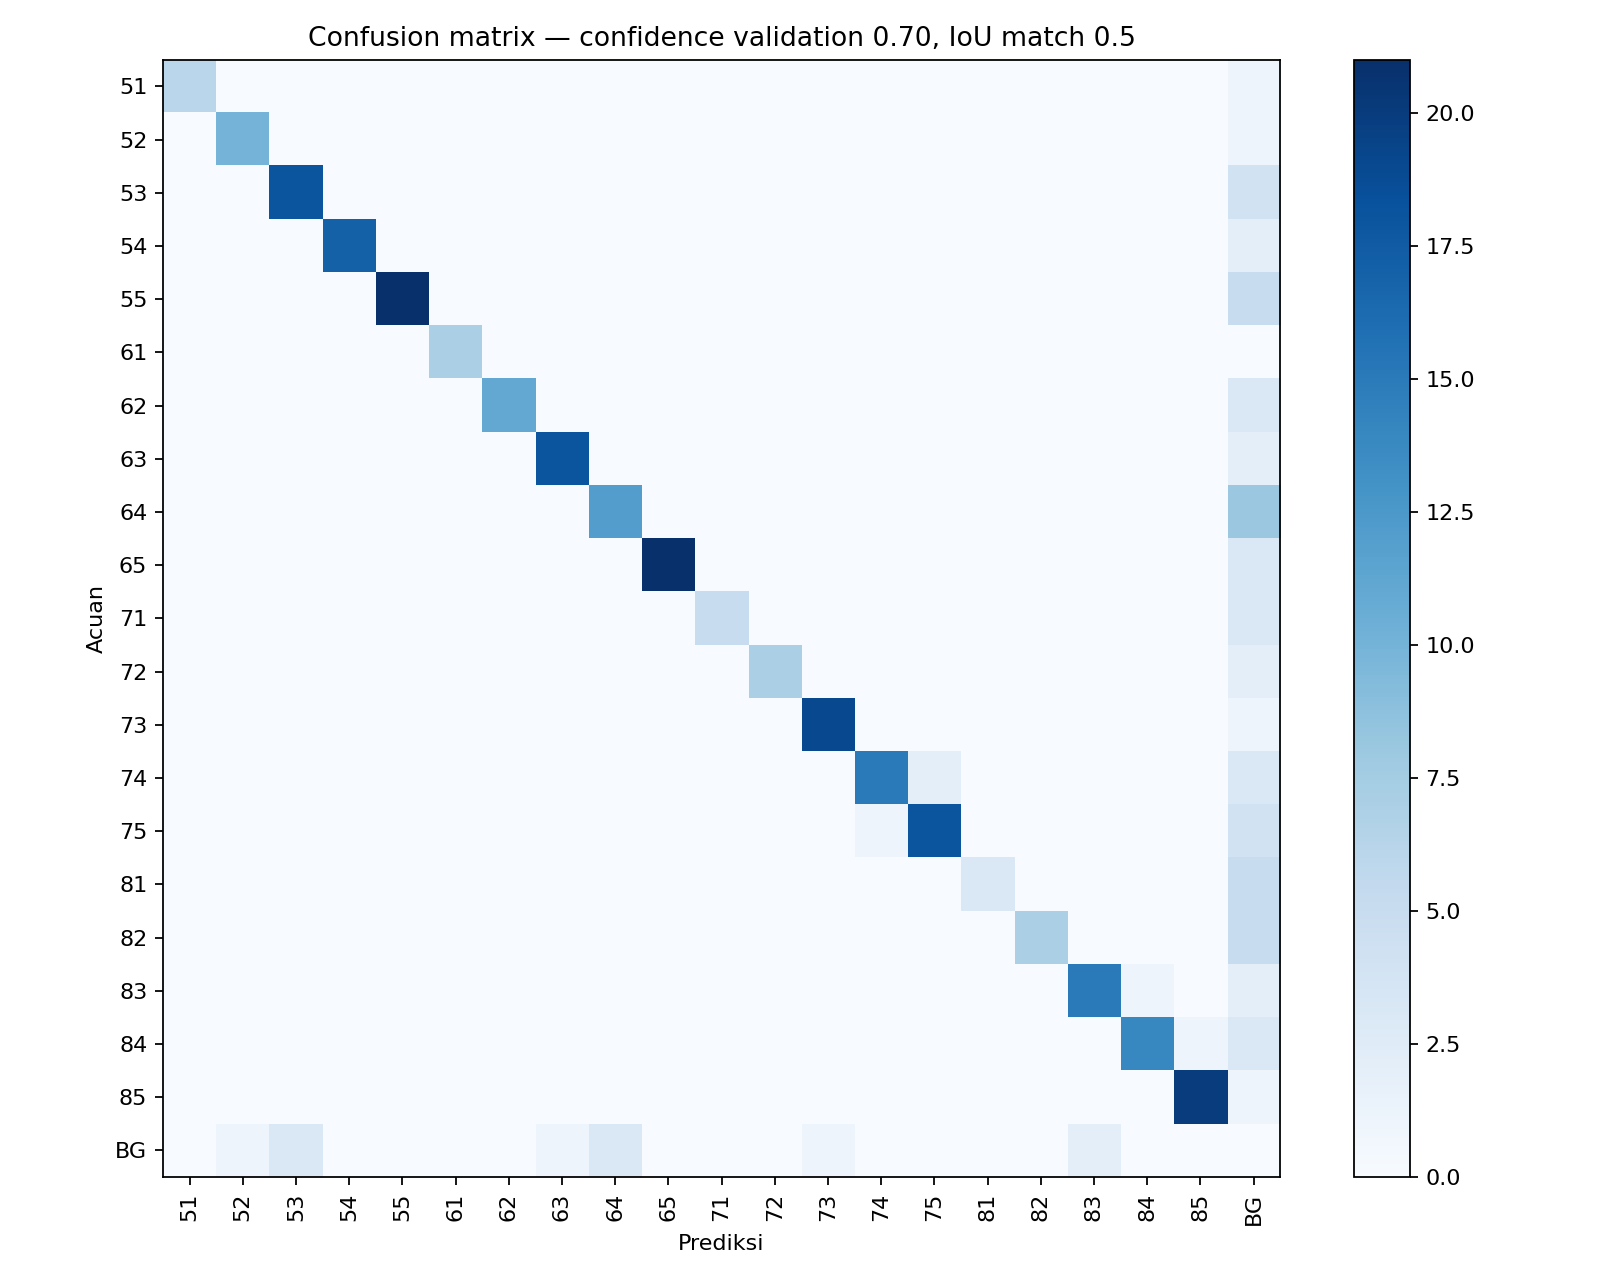

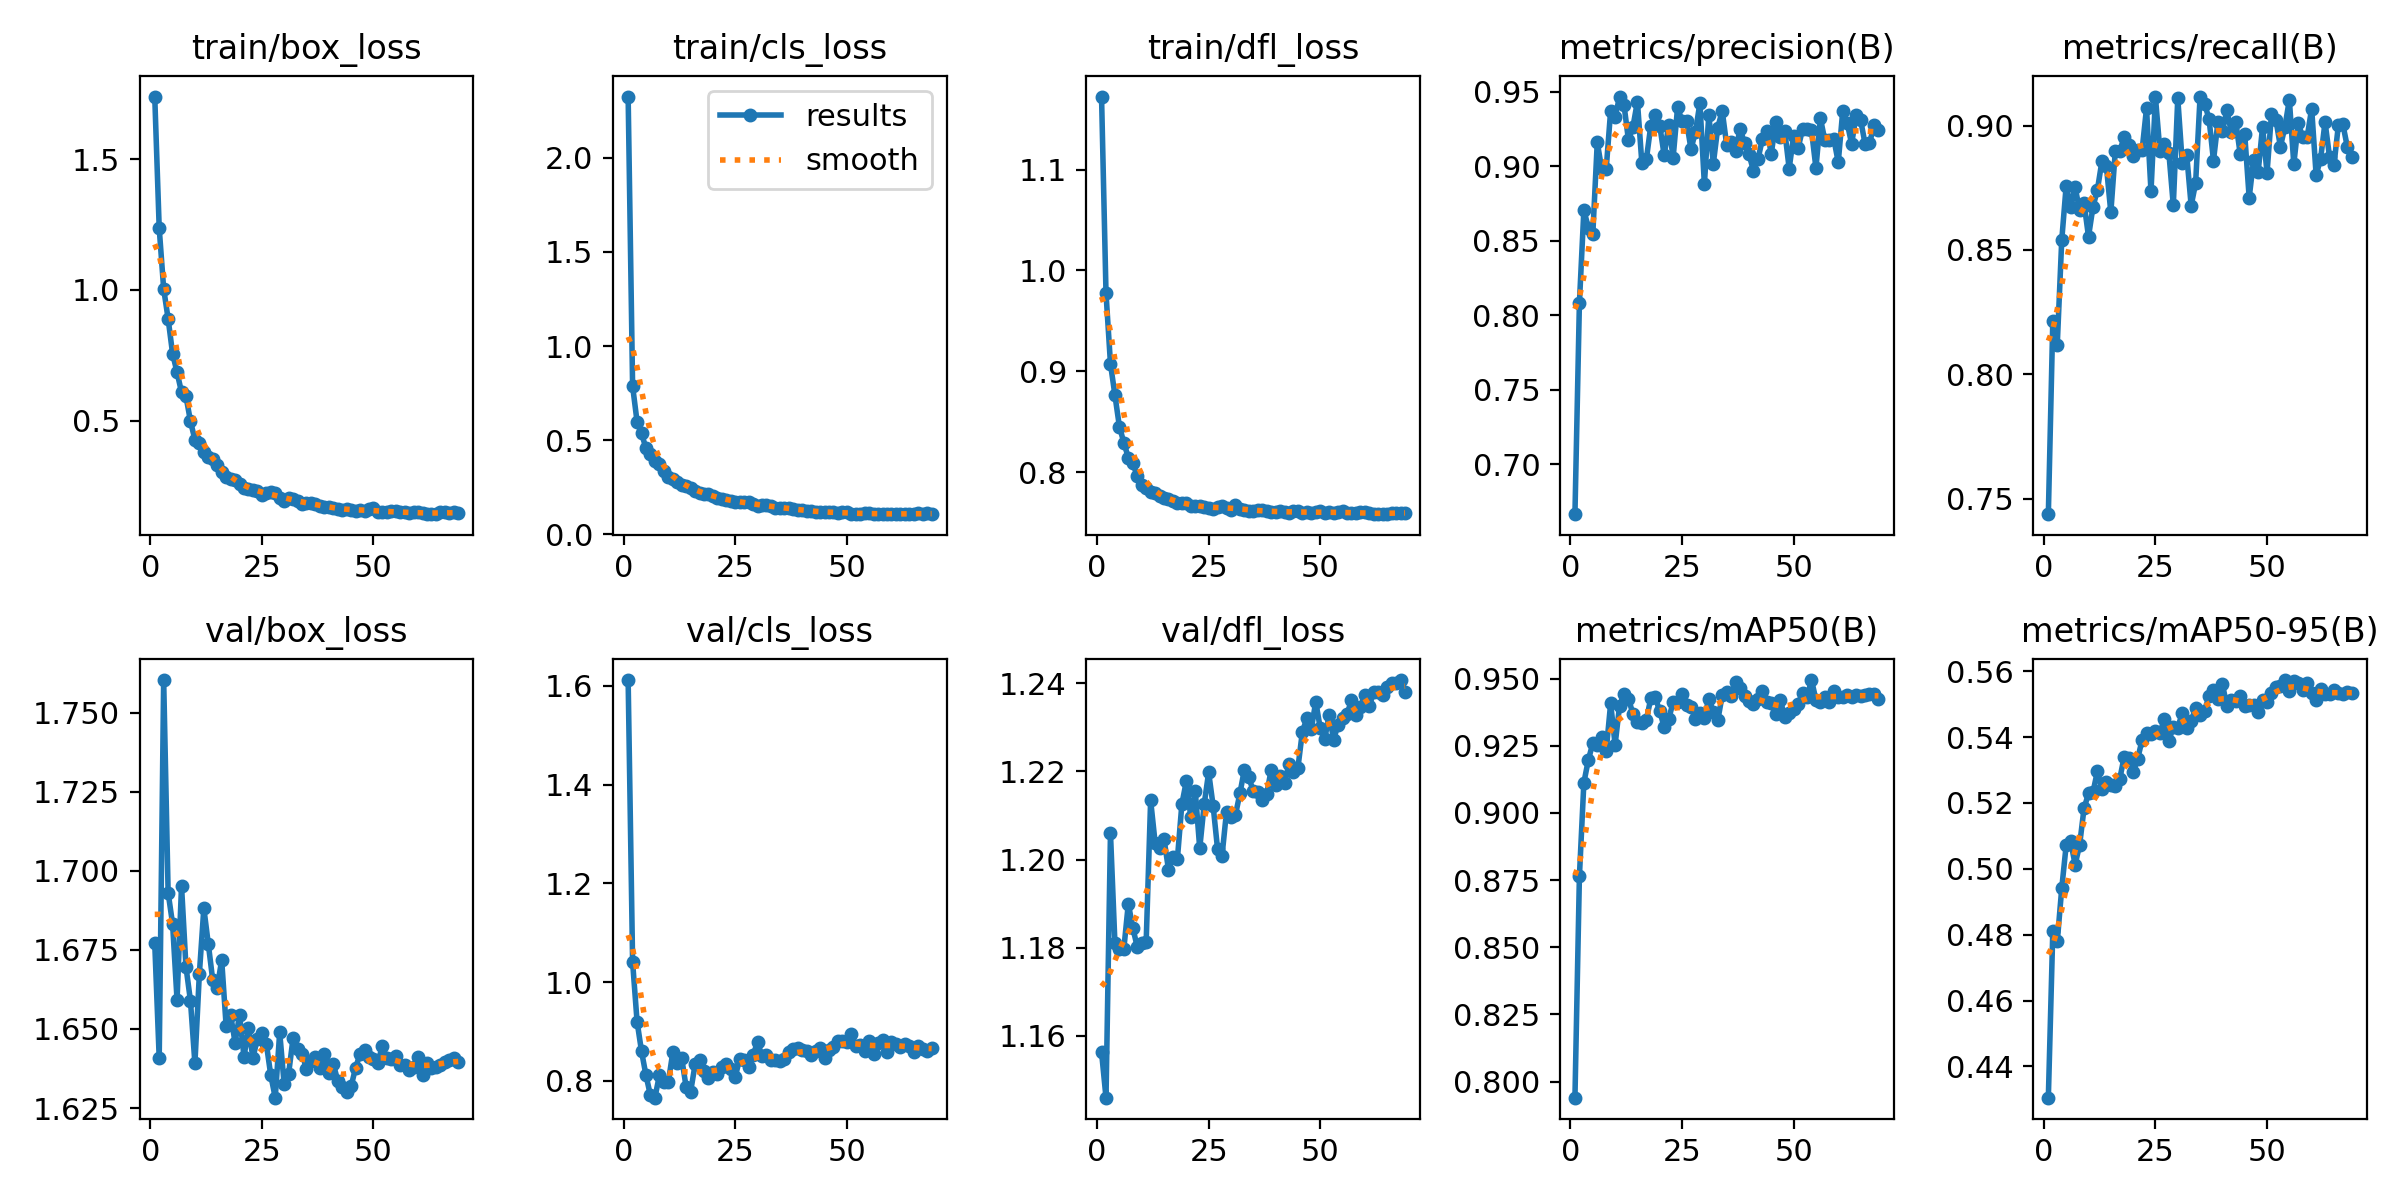

Selesai. Hasil aktual model: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_analisis/pemodelan/20261031_124203


In [9]:
from IPython.display import Image as DisplayImage,display
for name,info in models.items():
    print(name,'epoch aktual:',info['epochs_completed'])
    display(pd.read_csv(RUNS_HOME/name/'evaluasi'/'test_per_FDI.csv'))
    display(DisplayImage(filename=str(RUNS_HOME/name/'evaluasi'/'confusion_matrix_gt_rows.png')))
    training_curve=Path(info['save_dir'])/'results.png'
    if training_curve.is_file():display(DisplayImage(filename=str(training_curve)))
print('Selesai. Hasil aktual model:',RUNS_HOME)

## Catatan pelaporan
Jika memakai skor test untuk memilih satu eksperimen dan kemudian terus mengubah konfigurasi, test tidak lagi independen. Untuk penelitian utama, pilih ukuran/hyperparameter dari validation, kemudian laporkan test akhir. Pada tahap UTS, perbandingan dua model ditetapkan sebelum test. Jangan isi tabel laporan dengan angka dari data COCO atau artikel lain sebagai hasil dataset ini.